# ECS708U/P Machine Learning Coursework — Understanding Visual Data (Fashion-MNIST)

**Research question.** What structure exists in Fashion-MNIST, how can different machine-learning
models exploit that structure, and what do their successes and failures teach us about the data
and its representations?

This notebook runs top to bottom with *Restart and run all*. Expensive steps (MLP training)
are cached in `results/`; delete `results/runs/` and `results/checkpoints/` to retrain from scratch.

**Data roles (R1).** Train → fit parameters and scalers. Validation → every choice
(hyperparameters, checkpoints, K, thresholds). Test → used once, at the end, after the test plan is frozen.
Parts 0–3 below therefore report **validation** results only.

## Part 0 — Setup: data and computing (0.1, 0.2)

In [1]:
import json
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch

from src.data import CLASS_NAMES, SPLIT_SEED, get_splits, load_fashion_mnist
from src.register import log_experiment, show_register

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
pd.set_option("display.precision", 3)

FIG_DIR = "figures"
def savefig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", dpi=120)

# 0.2 Record the hardware and software used
print("Machine :", platform.machine(), "|", platform.processor() or "", "| OS:", platform.platform())
print("Python  :", platform.python_version())
print("torch", torch.__version__, "| sklearn", sklearn.__version__, "| numpy", np.__version__)
print("Compute : CPU only (torch threads = %d)" % torch.get_num_threads())

Machine : arm64 | arm | OS: macOS-26.6.2-arm64-arm-64bit
Python  : 3.11.7
torch 2.15.0 | sklearn 1.9.1 | numpy 2.4.6
Compute : CPU only (torch threads = 6)


### 0.1 Fixed data partitions

* The official 60,000 training images are split **stratified** into 50,000 train / 10,000 validation
  with `SPLIT_SEED = 708`. Indices are saved in `splits/splits.npz` and only ever loaded afterwards.
* **CPU-friendly option:** all supervised models in this notebook are fitted on a fixed stratified
  **10,000-image subset of the training partition** (`train_sub`). Validation and test sets are the full
  10,000 images. Using the subset keeps every experiment fast enough to repeat with several seeds,
  and it makes overfitting easier to observe.
* Clustering / feature-extraction subsets: 3,000 train (from the train partition), 1,000 validation
  (from the validation partition) and 1,000 test (from the official test set). The same images are
  used for every representation.
* Labels are used **only** to stratify. Pixel values are rescaled by the fixed constant 1/255,
  which is not learned from data and therefore cannot leak information.

In [2]:
t0 = time.time()
X_off, y_off, X_test, y_test = load_fashion_mnist()
splits = get_splits(y_off, y_test)
print(f"Loaded in {time.time() - t0:.1f}s; split seed = {int(splits['seed'][0])}")

X_tr, y_tr = X_off[splits["train_sub"]], y_off[splits["train_sub"]]   # fitting set (10k)
X_val, y_val = X_off[splits["val"]], y_off[splits["val"]]             # model selection (10k)
# X_test / y_test stay untouched until the final, frozen evaluation.

# Sanity checks: partitions are disjoint and inside the right sets
assert len(np.intersect1d(splits["train"], splits["val"])) == 0
assert np.isin(splits["train_sub"], splits["train"]).all()
assert np.isin(splits["cluster_train"], splits["train"]).all()
assert np.isin(splits["cluster_val"], splits["val"]).all()

sizes = {k: len(v) for k, v in splits.items() if k != "seed"}
counts = pd.DataFrame({
    "train (50k)": np.bincount(y_off[splits["train"]]),
    "val": np.bincount(y_val),
    "train_sub (fit)": np.bincount(y_tr),
    "cluster_train": np.bincount(y_off[splits["cluster_train"]]),
    "cluster_val": np.bincount(y_off[splits["cluster_val"]]),
    "cluster_test": np.bincount(y_test[splits["cluster_test"]]),
    "test": np.bincount(y_test),
}, index=CLASS_NAMES)
counts.loc["TOTAL"] = counts.sum()
print("Partition sizes:", sizes)
counts

Loaded in 0.7s; split seed = 708
Partition sizes: {'train': 50000, 'val': 10000, 'train_sub': 10000, 'cluster_train': 3000, 'cluster_val': 1000, 'cluster_test': 1000}


,train (50k),val,train_sub (fit),cluster_train,cluster_val,cluster_test,test
T-shirt/top,5000,1000,1000,300,100,100,1000
Trouser,5000,1000,1000,300,100,100,1000
Pullover,5000,1000,1000,300,100,100,1000
Dress,5000,1000,1000,300,100,100,1000
Coat,5000,1000,1000,300,100,100,1000
Sandal,5000,1000,1000,300,100,100,1000
Shirt,5000,1000,1000,300,100,100,1000
Sneaker,5000,1000,1000,300,100,100,1000
Bag,5000,1000,1000,300,100,100,1000
Ankle boot,5000,1000,1000,300,100,100,1000


**Table 0.1 (addresses 0.1).** Images per class in every partition. Each class is exactly 10% of every
partition, so stratification preserved the (already balanced) class proportions.

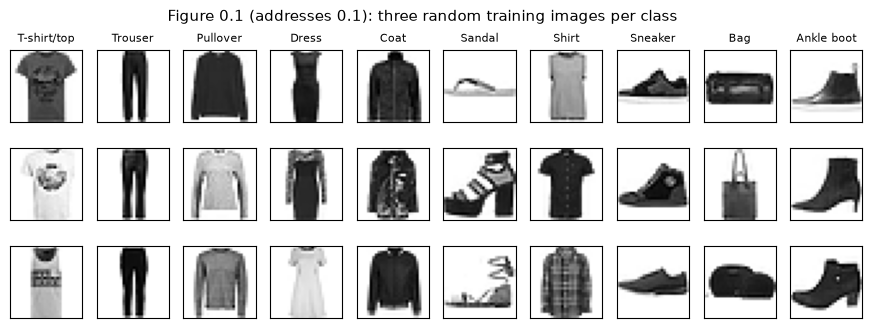

In [3]:
fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
rng = np.random.default_rng(0)
for c in range(10):
    idx = rng.choice(np.where(y_tr == c)[0], 3, replace=False)
    for r in range(3):
        ax = axes[r, c]
        ax.imshow(X_tr[idx[r]].reshape(28, 28), cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=8)
fig.suptitle("Figure 0.1 (addresses 0.1): three random training images per class")
savefig(fig, "fig0_1_examples")
plt.show()

Even from a few examples, the upper-body classes (T-shirt/top, Pullover, Coat, Shirt) look alike:
similar silhouettes with differences in sleeves, collars and texture. Footwear (Sandal, Sneaker,
Ankle boot) forms a second visually related group. We expect most confusions inside these groups.

---
## Part 1 — Classical classification

### 1.1 Models and why they suit this data

| Model | How it predicts | How it is fitted | Complexity control |
|---|---|---|---|
| **Multinomial logistic regression** (LR) | Computes one linear score $w_c^\top x + b_c$ per class, turns the scores into probabilities with softmax and predicts the most probable class. | Minimises the average cross-entropy plus an L2 penalty $\frac{1}{2C}\lVert W\rVert^2$ (L-BFGS). Pixels are standardised with a scaler fitted on the training set only. | `C`: small C → strong penalty → simpler, smoother model; large C → weaker penalty. |
| **k-nearest neighbours** (k-NN) | Finds the k training images closest in Euclidean pixel distance and takes a majority vote. | Nothing is optimised: it stores the training set. | `k`: k = 1 is the most flexible (memorises the training set); larger k averages over more neighbours → smoother boundary. |

**Why these two.** They sit at opposite ends of the model spectrum. LR is *parametric and linear*: it asks
whether the classes can be separated by hyperplanes in pixel space, and its probabilities support the
threshold study in 1.5. k-NN is *non-parametric and local*: it relies entirely on raw-pixel distance,
the same geometry that K-means uses in Part 4, so its errors directly show where pixel distance misleads.
k-NN uses unscaled pixels: all features already share the [0, 1] range, and standardising would inflate
near-constant border pixels.

Both models are fitted on the 10k fitting subset and selected on the validation set.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_lr(C):
    # The scaler is inside the pipeline, so it is fitted on training images only (R2).
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, max_iter=2000, random_state=0))

def make_knn(k):
    return KNeighborsClassifier(n_neighbors=k, metric="euclidean", n_jobs=-1)

### 1.4 Complexity study (run first, because it selects the settings used in 1.2–1.3)

Each model is refitted over a grid of its complexity parameter. We record training and validation
accuracy; the value with the best **validation** accuracy is kept for the rest of Part 1.
For k-NN, training accuracy is computed with each training image included in its own neighbourhood,
which is why k = 1 scores 100% on training data. That is the memorisation we want to show.

In [5]:
C_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]
k_grid = [1, 3, 5, 9, 15, 25, 51, 101]

lr_rows, knn_rows = [], []
for C in C_grid:
    t0 = time.time()
    m = make_lr(C).fit(X_tr, y_tr)
    lr_rows.append({"C": C, "train_acc": m.score(X_tr, y_tr), "val_acc": m.score(X_val, y_val),
                    "fit_s": time.time() - t0})
for k in k_grid:
    t0 = time.time()
    m = make_knn(k).fit(X_tr, y_tr)
    knn_rows.append({"k": k, "train_acc": m.score(X_tr, y_tr), "val_acc": m.score(X_val, y_val),
                     "time_s": time.time() - t0})
lr_cx, knn_cx = pd.DataFrame(lr_rows), pd.DataFrame(knn_rows)
best_C = float(lr_cx.loc[lr_cx.val_acc.idxmax(), "C"])
best_k = int(knn_cx.loc[knn_cx.val_acc.idxmax(), "k"])
print(f"Selected on validation: LR C = {best_C}, k-NN k = {best_k}")
display(lr_cx); display(knn_cx)

Selected on validation: LR C = 0.01, k-NN k = 5


,C,train_acc,val_acc,fit_s
0,1.000e-04,0.789,0.775,0.374
1,1.000e-03,0.850,0.829,0.643
2,1.000e-02,0.896,0.844,1.246
3,1.000e-01,0.935,0.832,1.790
4,1.000e+00,0.967,0.807,1.644
5,1.000e+01,0.985,0.786,2.932


,k,train_acc,val_acc,time_s
0,1,1.000,0.812,1.060
1,3,0.904,0.820,1.023
2,5,0.878,0.822,0.982
3,9,0.860,0.816,0.977
4,15,0.845,0.813,1.005
5,25,0.831,0.804,1.013
6,51,0.809,0.792,1.079
7,101,0.788,0.776,1.209


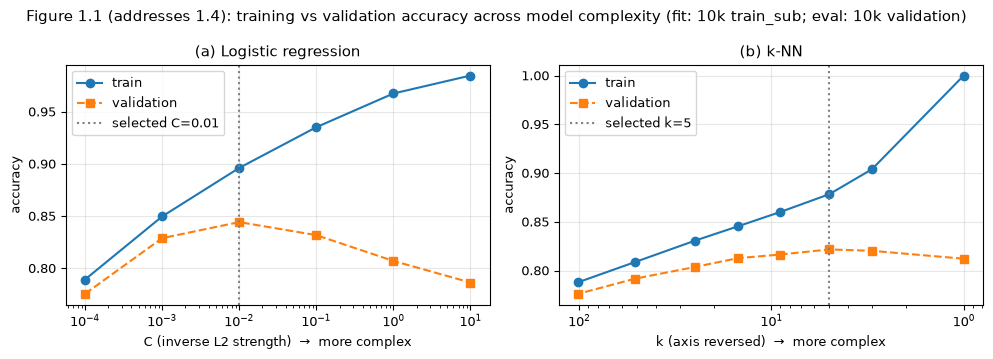

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.semilogx(lr_cx.C, lr_cx.train_acc, "o-", label="train")
ax.semilogx(lr_cx.C, lr_cx.val_acc, "s--", label="validation")
ax.axvline(best_C, color="grey", ls=":", label=f"selected C={best_C:g}")
ax.set_xlabel("C (inverse L2 strength)  →  more complex"); ax.set_ylabel("accuracy")
ax.set_title("(a) Logistic regression"); ax.legend()
ax = axes[1]
ax.semilogx(knn_cx.k, knn_cx.train_acc, "o-", label="train")
ax.semilogx(knn_cx.k, knn_cx.val_acc, "s--", label="validation")
ax.axvline(best_k, color="grey", ls=":", label=f"selected k={best_k}")
ax.invert_xaxis()
ax.set_xlabel("k (axis reversed)  →  more complex"); ax.set_ylabel("accuracy")
ax.set_title("(b) k-NN"); ax.legend()
fig.suptitle("Figure 1.1 (addresses 1.4): training vs validation accuracy across model complexity "
             "(fit: 10k train_sub; eval: 10k validation)")
fig.tight_layout(); savefig(fig, "fig1_1_complexity"); plt.show()

log_experiment(id="E1.4a", task="1.4", question="How does L2 strength affect LR generalisation?",
               hypothesis="Very small C underfits; very large C widens the train-val gap",
               changed_variable="C in " + str(C_grid), fixed_conditions="standardised pixels, lbfgs, max_iter=2000",
               split="fit train_sub / eval val", seed=0, configuration="LogisticRegression multinomial",
               metric="accuracy", result=f"best C={best_C}, val_acc={lr_cx.val_acc.max():.4f}",
               output_path="figures/fig1_1_complexity.png")
log_experiment(id="E1.4b", task="1.4", question="How does k affect k-NN generalisation?",
               hypothesis="k=1 memorises (train 100%); moderate k best on validation",
               changed_variable="k in " + str(k_grid), fixed_conditions="raw pixels, Euclidean, uniform vote",
               split="fit train_sub / eval val", seed="n/a (deterministic)", configuration="KNeighborsClassifier",
               metric="accuracy", result=f"best k={best_k}, val_acc={knn_cx.val_acc.max():.4f}",
               output_path="figures/fig1_1_complexity.png");

**Analysis 1.4 (complexity and generalisation).**
* *Observation.* For both models, training accuracy rises steadily as complexity grows
  (LR: 0.789 → 0.985 as C goes 1e-4 → 10; k-NN: 0.788 → 1.000 as k goes 101 → 1). Validation accuracy
  instead rises and then falls: LR peaks at **C = 0.01 (0.844)**, k-NN peaks at **k = 5 (0.822)**.
* *Interpretation.* On the left of each panel the model is too simple (underfitting): train and
  validation are both low and close together, so the error comes from bias. On the right the
  train–validation gap widens (LR at C = 10: 0.985 vs 0.786, a 20-point gap; k-NN at k = 1: 1.000 vs 0.812).
  The model is fitting details of these particular 10k images that do not carry over to new images (variance).
  The best validation point balances the two. This is the bias–variance trade-off.
* Even a linear model can overfit: with 784 inputs × 10 classes ≈ 7,850 weights and only 10k images,
  weak regularisation lets LR fit noise. k-NN's validation curve is flat between k = 3 and k = 15
  (0.816–0.822), so its exact choice of k matters little.
* *Caveat.* The difference between the best and runner-up settings (e.g. k = 3 vs 5: 0.820 vs 0.822) is
  about 20 images out of 10,000 and should not be over-interpreted.

### 1.2 Metrics: overall and per class (validation set, selected models)

In [7]:
lr = make_lr(best_C).fit(X_tr, y_tr)
knn = make_knn(best_k).fit(X_tr, y_tr)
t0 = time.time(); pred_lr = lr.predict(X_val); proba_lr = lr.predict_proba(X_val); t_lr = time.time() - t0
t0 = time.time(); pred_knn = knn.predict(X_val); t_knn = time.time() - t0
print(f"Validation prediction time: LR {t_lr:.2f}s, k-NN {t_knn:.2f}s (10,000 images)")

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(10), zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=CLASS_NAMES)

tab_lr, tab_knn = per_class_table(y_val, pred_lr), per_class_table(y_val, pred_knn)
summary = pd.concat({f"LR (C={best_C:g})": tab_lr, f"k-NN (k={best_k})": tab_knn}, axis=1)
acc_lr, acc_knn = accuracy_score(y_val, pred_lr), accuracy_score(y_val, pred_knn)
print(f"Overall validation accuracy: LR {acc_lr:.4f} ({(pred_lr == y_val).sum()}/{len(y_val)}),  "
      f"k-NN {acc_knn:.4f} ({(pred_knn == y_val).sum()}/{len(y_val)})")
summary

Validation prediction time: LR 0.01s, k-NN 0.48s (10,000 images)
Overall validation accuracy: LR 0.8442 (8442/10000),  k-NN 0.8216 (8216/10000)


LR (C=0.01)                       k-NN (k=5)                      
              precision recall     f1 support  precision recall     f1 support
T-shirt/top       0.786  0.822  0.804    1000      0.720  0.849  0.779    1000
Trouser           0.968  0.972  0.970    1000      0.989  0.953  0.970    1000
Pullover          0.744  0.757  0.751    1000      0.687  0.788  0.734    1000
Dress             0.853  0.854  0.854    1000      0.853  0.854  0.854    1000
Coat              0.750  0.747  0.748    1000      0.741  0.701  0.720    1000
Sandal            0.933  0.910  0.922    1000      0.992  0.757  0.859    1000
Shirt             0.619  0.576  0.597    1000      0.623  0.505  0.558    1000
Sneaker           0.906  0.912  0.909    1000      0.840  0.925  0.881    1000
Bag               0.946  0.947  0.947    1000      0.969  0.923  0.945    1000
Ankle boot        0.925  0.945  0.935    1000      0.846  0.961  0.900    1000

**Table 1.1 (addresses 1.2).** Per-class precision, recall and F1 on the validation set, with the number of
true images per class (*support*). Recall = correct / support for that class; precision = correct / all
images predicted as that class.

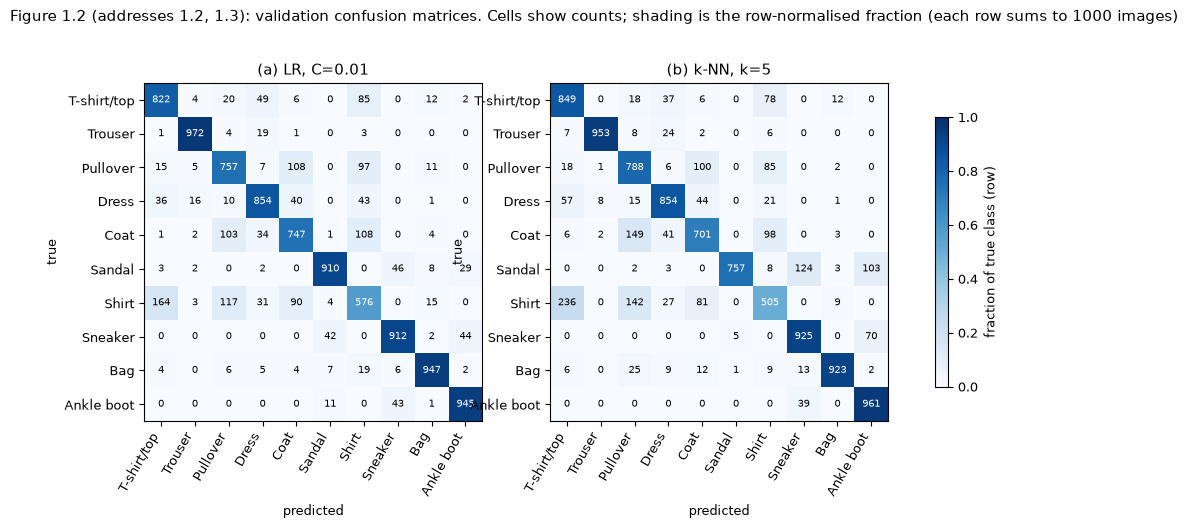

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, name in [(axes[0], pred_lr, f"(a) LR, C={best_C:g}"), (axes[1], pred_knn, f"(b) k-NN, k={best_k}")]:
    cm = confusion_matrix(y_val, pred, labels=range(10))
    im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 500 else "black")
    ax.set_xticks(range(10), CLASS_NAMES, rotation=60, ha="right"); ax.set_yticks(range(10), CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.7, label="fraction of true class (row)")
fig.suptitle("Figure 1.2 (addresses 1.2, 1.3): validation confusion matrices. Cells show counts; "
             "shading is the row-normalised fraction (each row sums to 1000 images)")
savefig(fig, "fig1_2_confusion"); plt.show()

log_experiment(id="E1.2", task="1.2", question="How well do the selected LR and k-NN classify each class?",
               hypothesis="Upper-body garments (Shirt, Pullover, Coat, T-shirt) are hardest",
               changed_variable="model", fixed_conditions="same train_sub / same val images",
               split="fit train_sub / eval val", seed=0,
               configuration=f"LR C={best_C}; kNN k={best_k}", metric="accuracy, per-class P/R/F1",
               result=f"LR {acc_lr:.4f}; kNN {acc_knn:.4f}", output_path="figures/fig1_2_confusion.png");

### 1.3 Error analysis: comparing the two models on the same images

In [9]:
ok_lr, ok_knn = pred_lr == y_val, pred_knn == y_val
agree = pd.DataFrame([[np.sum(ok_lr & ok_knn), np.sum(ok_lr & ~ok_knn)],
                      [np.sum(~ok_lr & ok_knn), np.sum(~ok_lr & ~ok_knn)]],
                     index=["LR correct", "LR wrong"], columns=["k-NN correct", "k-NN wrong"])
both_wrong_same = np.sum(~ok_lr & ~ok_knn & (pred_lr == pred_knn))
print(f"Both wrong on {agree.iloc[1, 1]} images; on {both_wrong_same} of them they predict the SAME wrong class.")
display(agree)

per_class_err = pd.DataFrame({
    "support": np.bincount(y_val, minlength=10),
    "both correct": np.bincount(y_val[ok_lr & ok_knn], minlength=10),
    "only LR correct": np.bincount(y_val[ok_lr & ~ok_knn], minlength=10),
    "only k-NN correct": np.bincount(y_val[~ok_lr & ok_knn], minlength=10),
    "both wrong": np.bincount(y_val[~ok_lr & ~ok_knn], minlength=10)}, index=CLASS_NAMES)
per_class_err

Both wrong on 1013 images; on 754 of them they predict the SAME wrong class.


,k-NN correct,k-NN wrong
LR correct,7671,771
LR wrong,545,1013


,support,both correct,only LR correct,only k-NN correct,both wrong
T-shirt/top,1000,772,50,77,101
Trouser,1000,946,26,7,21
Pullover,1000,662,95,126,117
Dress,1000,807,47,47,99
Coat,1000,608,139,93,160
Sandal,1000,745,165,12,78
Shirt,1000,416,160,89,335
Sneaker,1000,874,38,51,37
Bag,1000,911,36,12,41
Ankle boot,1000,930,15,31,24


**Table 1.2 (addresses 1.3).** Agreement between the two models on the *same* 10,000 validation images,
overall and per true class.

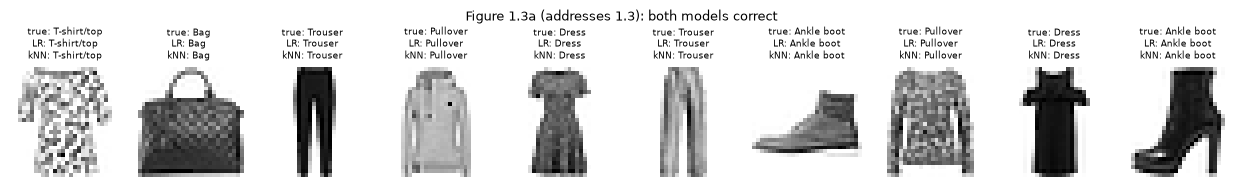

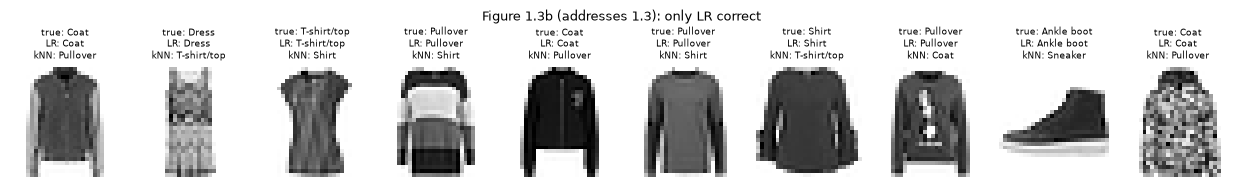

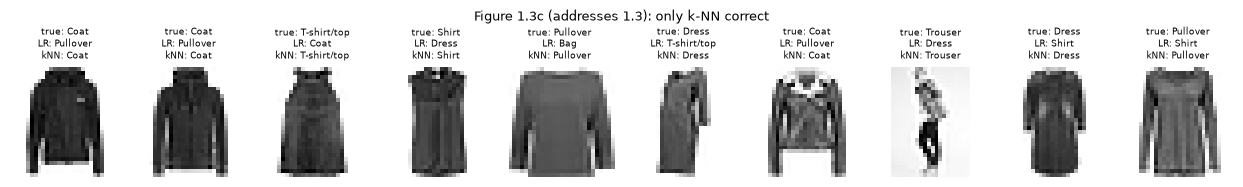

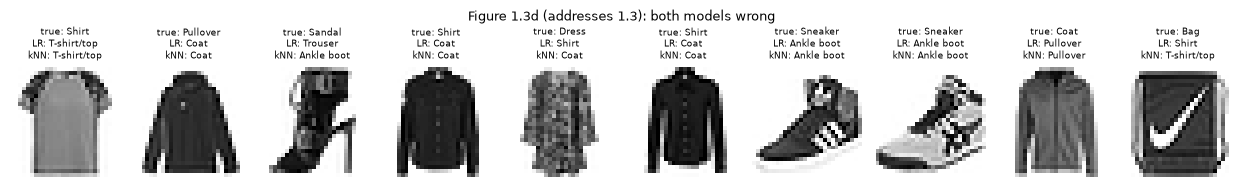

In [10]:
def show_grid(indices, title, fname, n=10):
    rng = np.random.default_rng(1)
    indices = rng.choice(indices, min(n, len(indices)), replace=False) if len(indices) else []
    fig, axes = plt.subplots(1, n, figsize=(1.25 * n, 2.0))
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, indices):
        ax.imshow(X_val[i].reshape(28, 28), cmap="gray_r")
        ax.set_title(f"true: {CLASS_NAMES[y_val[i]]}\nLR: {CLASS_NAMES[pred_lr[i]]}\n"
                     f"kNN: {CLASS_NAMES[pred_knn[i]]}", fontsize=6.5)
    fig.suptitle(title, fontsize=9); fig.tight_layout(); savefig(fig, fname); plt.show()

show_grid(np.where(ok_lr & ok_knn)[0], "Figure 1.3a (addresses 1.3): both models correct", "fig1_3a_both_correct")
show_grid(np.where(ok_lr & ~ok_knn)[0], "Figure 1.3b (addresses 1.3): only LR correct", "fig1_3b_only_lr")
show_grid(np.where(~ok_lr & ok_knn)[0], "Figure 1.3c (addresses 1.3): only k-NN correct", "fig1_3c_only_knn")
show_grid(np.where(~ok_lr & ~ok_knn)[0], "Figure 1.3d (addresses 1.3): both models wrong", "fig1_3d_both_wrong")

In [11]:
cm_l, cm_k = confusion_matrix(y_val, pred_lr), confusion_matrix(y_val, pred_knn)
pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append({"true": CLASS_NAMES[i], "predicted": CLASS_NAMES[j],
                          "LR errors": cm_l[i, j], "k-NN errors": cm_k[i, j]})
top_pairs = pd.DataFrame(pairs).assign(total=lambda d: d["LR errors"] + d["k-NN errors"]) \
    .sort_values("total", ascending=False).head(8).reset_index(drop=True)
top_pairs

,true,predicted,LR errors,k-NN errors,total
0,Shirt,T-shirt/top,164,236,400
1,Shirt,Pullover,117,142,259
2,Coat,Pullover,103,149,252
3,Pullover,Coat,108,100,208
4,Coat,Shirt,108,98,206
5,Pullover,Shirt,97,85,182
6,Shirt,Coat,90,81,171
7,Sandal,Sneaker,46,124,170


**Table 1.3 (addresses 1.3).** The eight most frequent confusions (true → predicted) on validation, out of
1,000 images per true class.

**Analysis 1.3 (easy and hard classes, and what the errors tell us).**
* *Observation.* **Easy classes**: Trouser, Bag and Ankle boot (≥ 0.92 recall for both models). Their
  silhouettes are distinctive: two legs, a box with a handle, a tall boot shape. **Hard classes**: Shirt
  (recall 0.576 LR / 0.505 k-NN), then Coat and Pullover (~0.70–0.79). Every top-7 confusion in Table 1.3
  is *between upper-body garments* (Shirt → T-shirt/top is the largest: 164 LR and 236 k-NN errors out of
  1,000 shirts). The only cross-group exception in the top 8 is Sandal → Sneaker.
* *Observation.* The two models agree a lot: 7,671 images are correct for both, and on 754 of the
  1,013 images where both are wrong they make the **same** wrong prediction.
* *Interpretation.* Errors made by two very different models (one linear and global, one local and
  memory-based) are likely caused by the **data/representation**, not by a particular model. In raw
  pixels, a shirt and a T-shirt are close: both are a bright torso-shaped blob. The distinguishing cues
  (sleeve length, buttons, collar) occupy few pixels, so they contribute little to Euclidean distance or
  to a linear score. Some "both wrong" images (Figure 1.3d) are genuinely ambiguous even to a human.
* *Where they differ.* LR wins clearly on **Sandal** (165 vs 12 images that only one model gets right).
  Sandals are sparse, strappy images whose pixel pattern varies a lot, so their nearest neighbours in
  pixel space are often sneakers (k-NN: 124 Sandal → Sneaker errors vs 46 for LR). LR instead learns which
  pixels matter (e.g. the empty gaps of a sandal). k-NN is relatively better on Pullover and T-shirt/top,
  where a close stored example of the same style can beat a single linear boundary (Figure 1.3c).
* *Hypothesis for later parts.* The upper-body group should also appear merged when we cluster raw
  pixels (Part 4), and a representation learned with labels (Part 5) should separate it better.

### 1.5 Decisions and costs: a binary decision with a threshold

**Decision problem (my own).** A returns warehouse sorts items automatically and sends anything it
believes is a **Shirt** to a manual inspection station (shirts are often returned for button and collar
damage). Positive = Shirt, negative = any other class.
* **False negative (FN)**: a Shirt is not inspected → a damaged item may be resold (costly).
* **False positive (FP)**: a non-Shirt is inspected → a few minutes of staff time are wasted (cheap).

We use the LR probability $p(\text{Shirt}\mid x)$ as a score and predict *Shirt* when it is $\ge t$.
Shirt is the hardest class (Table 1.1), so it is the problem where the threshold matters most.
For illustration we assume an FN costs **5×** an FP and choose $t$ on **validation** data to minimise
the total cost. The default argmax rule corresponds to roughly $t\approx 0.5$.

Positives (Shirt) = 1000, negatives = 9000;  ROC-AUC = 0.935


,t,TP,FP,FN,TN,FNR (missed shirts),FPR (false alarms),precision,"cost (FN=5, FP=1)"
9,0.10,872,1504,128,7496,0.128,0.167,0.367,2144
18,0.19,789,911,211,8089,0.211,0.101,0.464,1966
19,0.20,781,871,219,8129,0.219,0.097,0.473,1966
29,0.30,685,544,315,8456,0.315,0.060,0.557,2119
49,0.50,500,237,500,8763,0.500,0.026,0.678,2737
69,0.70,302,88,698,8912,0.698,0.010,0.774,3578
89,0.90,56,15,944,8985,0.944,0.002,0.789,4735


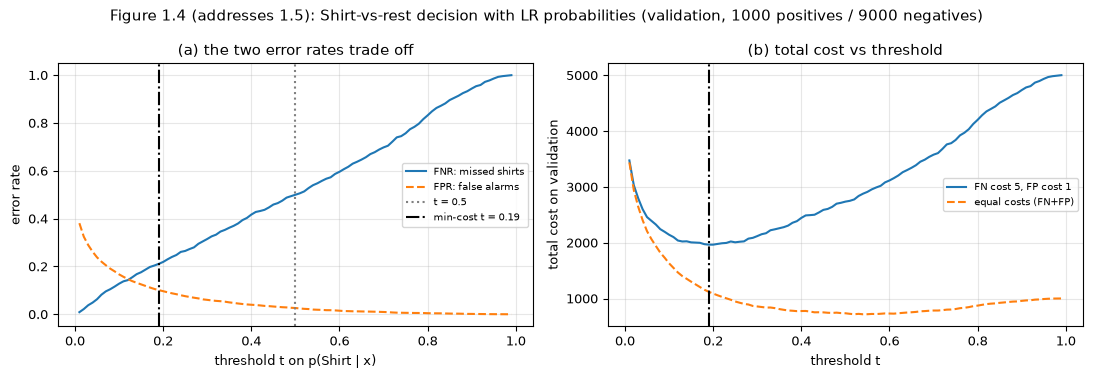

In [12]:
from sklearn.metrics import precision_recall_curve, roc_auc_score

POS = CLASS_NAMES.index("Shirt")
score = proba_lr[:, POS]; is_pos = (y_val == POS)
thresholds = np.linspace(0.01, 0.99, 99)
rows = []
for t in thresholds:
    pred_pos = score >= t
    tp = np.sum(pred_pos & is_pos); fp = np.sum(pred_pos & ~is_pos)
    fn = np.sum(~pred_pos & is_pos); tn = np.sum(~pred_pos & ~is_pos)
    rows.append({"t": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "FNR (missed shirts)": fn / is_pos.sum(), "FPR (false alarms)": fp / (~is_pos).sum(),
                 "precision": tp / max(tp + fp, 1), "cost (FN=5, FP=1)": 5 * fn + fp})
thr = pd.DataFrame(rows)
t_cost = thr.loc[thr["cost (FN=5, FP=1)"].idxmin(), "t"]
t_half = thr.iloc[(thr.t - 0.5).abs().argmin()]
print(f"Positives (Shirt) = {is_pos.sum()}, negatives = {(~is_pos).sum()};  ROC-AUC = {roc_auc_score(is_pos, score):.3f}")
display(thr[thr.t.round(2).isin([0.1, 0.2, 0.3, round(t_cost, 2), 0.5, 0.7, 0.9])].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(thr.t, thr["FNR (missed shirts)"], "-", label="FNR: missed shirts")
ax.plot(thr.t, thr["FPR (false alarms)"], "--", label="FPR: false alarms")
ax.axvline(0.5, color="grey", ls=":", label="t = 0.5")
ax.axvline(t_cost, color="k", ls="-.", label=f"min-cost t = {t_cost:.2f}")
ax.set_xlabel("threshold t on p(Shirt | x)"); ax.set_ylabel("error rate"); ax.legend(fontsize=7)
ax.set_title("(a) the two error rates trade off")
ax = axes[1]
ax.plot(thr.t, thr["cost (FN=5, FP=1)"], "-", label="FN cost 5, FP cost 1")
ax.plot(thr.t, thr.FN + thr.FP, "--", label="equal costs (FN+FP)")
ax.axvline(t_cost, color="k", ls="-.")
ax.set_xlabel("threshold t"); ax.set_ylabel("total cost on validation"); ax.legend(fontsize=7)
ax.set_title("(b) total cost vs threshold")
fig.suptitle("Figure 1.4 (addresses 1.5): Shirt-vs-rest decision with LR probabilities "
             f"(validation, {is_pos.sum()} positives / {(~is_pos).sum()} negatives)")
fig.tight_layout(); savefig(fig, "fig1_4_threshold"); plt.show()

log_experiment(id="E1.5", task="1.5", question="How does the threshold trade missed shirts against false alarms?",
               hypothesis="With FN 5x costlier, the best threshold is well below 0.5",
               changed_variable="threshold t in [0.01, 0.99]", fixed_conditions=f"LR C={best_C}, validation scores",
               split="fit train_sub / eval val", seed=0, configuration="Shirt (pos) vs rest, cost FN=5 FP=1",
               metric="FNR, FPR, total cost", result=f"min-cost t={t_cost:.2f}",
               output_path="figures/fig1_4_threshold.png");

**Analysis 1.5 (threshold trade-off).**
* *Observation.* Lowering the threshold catches more shirts but raises more false alarms (Figure 1.4a):
  at t = 0.5 the system misses **50%** of shirts (FNR 0.50) with a 2.6% false-alarm rate; at t = 0.1 it
  misses only 12.8% but flags 16.7% of non-shirts (1,504 items). ROC-AUC = 0.935, so the score ranks
  shirts above non-shirts well, but the classes overlap.
* With FN cost 5 and FP cost 1, validation cost is minimised at **t ≈ 0.19–0.20** (cost 1,966 vs 2,737 at
  t = 0.5, a 28% reduction). The cost curve is flat around its minimum, so the precise value is not critical.
* *Interpretation.* The probability threshold is a **decision** choice separate from the model. The
  default 0.5 implicitly assumes equal costs, and under the stated costs it is far from optimal. Precision
  at the chosen threshold is only ~0.46, because negatives outnumber positives 9:1: even a modest FPR
  creates many false alarms.
* *Caveat.* The threshold is chosen on validation. Its cost on unseen data will be measured once in the
  final test evaluation, and the 5:1 cost ratio is an assumption of the scenario, not a measured fact.

---
## Part 2 — Neural networks: architecture and learning

### 2.1 Baseline MLP (trained from scratch)

All code is in `src/mlp.py`. The parts below are printed so the model, loss, gradient update,
training loop and validation loop can be read directly.

| Item | Baseline choice | Why |
|---|---|---|
| Input | 784 pixels in [0, 1] (fixed /255 scaling) | same input as the classical models |
| Architecture | 784 → **256** → ReLU → **128** → ReLU → 10 logits | two hidden layers let it learn non-linear combinations of pixels, which LR cannot; the funnel shape compresses to a 128-d representation used in Part 5 |
| Loss | cross-entropy on softmax(logits) | the negative log-likelihood for a categorical label; same loss as LR, so differences come from the architecture |
| Optimiser | mini-batch SGD with momentum, **lr = 0.05**, momentum 0.9, batch 128, **written by hand** | simple, well understood; momentum smooths noisy minibatch gradients |
| Epochs | 60 (≈ 4,700 updates) | long enough for training loss to approach zero, so overfitting becomes visible |
| Initialisation | Kaiming-normal weights, zero biases | keeps activation scale stable through ReLU layers |
| Checkpoint rule | keep the epoch with the **highest validation accuracy** (earliest on ties); all 60 epochs are still run so full curves are recorded | selection uses validation only (R1) |
| Regularisation | none (no weight decay, no dropout) | an unregularised baseline for Part 3 |
| Seed | 0: controls initialisation, minibatch order and dropout masks | the split is fixed separately (seed 708) |

**How it predicts.** Each layer computes $h = \mathrm{ReLU}(Wh_{prev} + b)$. The last layer outputs 10 scores
(logits) $z$; $p(c\mid x) = e^{z_c}/\sum_j e^{z_j}$ and the prediction is $\arg\max_c z_c$.

**How it learns.** For each minibatch: forward pass → cross-entropy loss → `loss.backward()` runs
backpropagation, which applies the chain rule layer by layer from the loss back to the input and gives
$\partial L/\partial w$ for every weight → `sgd_momentum_step` updates $v \leftarrow \mu v + g$,
$w \leftarrow w - \eta v$. After every epoch, a validation loop measures loss and accuracy with gradients off.

In [13]:
import inspect
from src import mlp as mlp_mod
from src.mlp import BASELINE, MLP, count_params, predict_proba, run

for fn in [mlp_mod.MLP, mlp_mod.sgd_momentum_step, mlp_mod.evaluate, mlp_mod.train]:
    print(inspect.getsource(fn))

class MLP(nn.Module):
    """784 -> hidden[0] -> ... -> hidden[-1] -> 10, ReLU after every hidden layer.

    forward(x) returns logits (unnormalised class scores); softmax is applied
    inside the cross-entropy loss. features(x) returns the activations of the
    final hidden layer (used as a learned representation in Part 5).
    """

    def __init__(self, hidden=(256, 128), dropout=0.0):
        super().__init__()
        layers, d_in = [], 784
        for h in hidden:
            layers += [nn.Linear(d_in, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))  # active only in model.train() mode
            d_in = h
        self.hidden = nn.Sequential(*layers)
        self.out = nn.Linear(d_in, 10)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                # He/Kaiming initialisation keeps activation variance stable through ReLU layers
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
    

In [14]:
def mlp_run(exp_id, **overrides):
    cfg = {**BASELINE, **overrides}
    model, hist = run(exp_id, cfg, X_tr, y_tr, X_val, y_val)
    return model, hist

t0 = time.time()
base_model, base_hist = mlp_run("E2.1_baseline")
print(base_model)
print(f"Trainable parameters: {count_params(base_model):,}  "
      f"(784·256+256 + 256·128+128 + 128·10+10 = {784*256+256 + 256*128+128 + 128*10+10:,})")
print(f"Best validation accuracy {base_hist['best_val_acc']:.4f} at epoch {base_hist['best_epoch']}; "
      f"training time {base_hist['train_time_s']:.1f}s (CPU)")
log_experiment(id="E2.1", task="2.1", question="How well does a from-scratch MLP do on Fashion-MNIST?",
               hypothesis="Better than LR (0.844) because hidden layers learn non-linear features",
               changed_variable="- (baseline)", fixed_conditions="see BASELINE in src/mlp.py",
               split="fit train_sub / select+eval val", seed=0, configuration=json.dumps(BASELINE),
               metric="val accuracy at best epoch", result=f"{base_hist['best_val_acc']:.4f} @ ep {base_hist['best_epoch']}",
               output_path="results/runs/E2.1_baseline.json");

MLP(
  (hidden): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
  )
  (out): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 235,146  (784·256+256 + 256·128+128 + 128·10+10 = 235,146)
Best validation accuracy 0.8729 at epoch 27; training time 4.9s (CPU)


In [15]:
STYLES = [dict(marker="o", ls="-"), dict(marker="s", ls="--"), dict(marker="^", ls="-."),
          dict(marker="D", ls=":"), dict(marker="v", ls=(0, (5, 1)))]

def plot_curves(hists, labels, title, fname):
    """Four panels: train loss, validation loss, train accuracy, validation accuracy.
    Lines differ by marker and dash pattern (not colour alone). A star marks the checkpoint epoch."""
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
    panels = [("train_loss", "(a) training loss (CE)"), ("val_loss", "(b) validation loss (CE)"),
              ("train_acc", "(c) training accuracy"), ("val_acc", "(d) validation accuracy")]
    for ax, (key, name) in zip(axes, panels):
        for h, lab, st in zip(hists, labels, STYLES):
            ep = np.arange(1, len(h[key]) + 1)
            line, = ax.plot(ep, h[key], label=lab, markevery=10, ms=4, **st)
            if key == "val_acc":
                ax.plot(h["best_epoch"], h["best_val_acc"], "*", ms=12, color=line.get_color(), mec="k")
        ax.set_title(name); ax.set_xlabel("epoch")
        if "loss" in key: ax.set_ylim(0, min(2.0, ax.get_ylim()[1]))
    axes[0].legend(fontsize=7)
    fig.suptitle(title); fig.tight_layout(); savefig(fig, fname); plt.show()

def summarise(hists, labels):
    rows = []
    for h, lab in zip(hists, labels):
        b = h["best_epoch"] - 1
        rows.append({"config": lab, "params": h["n_params"], "best epoch": h["best_epoch"],
                     "val acc (checkpoint)": h["best_val_acc"], "train acc (checkpoint)": h["train_acc"][b],
                     "min train loss": np.nanmin(h["train_loss"]), "final train acc": h["train_acc"][-1],
                     "final val acc": h["val_acc"][-1], "final val loss": h["val_loss"][-1],
                     "train time (s)": h["train_time_s"]})
    return pd.DataFrame(rows).set_index("config")

### 2.2 Experiment A: capacity

**Changed variable:** hidden-layer widths (depth fixed at two hidden layers).
**Fixed:** everything else in the baseline recipe (optimiser, lr, batch, 60 epochs, init, seed 0, data).

* Small: 784 → 32 → 16 → 10 (~10× fewer parameters)
* Baseline: 784 → 256 → 128 → 10
* Large: 784 → 1024 → 512 → 10 (~6× more parameters)

*Hypothesis:* more capacity → lower training loss; validation improves only while the extra capacity
captures real structure, and then the train–validation gap grows.

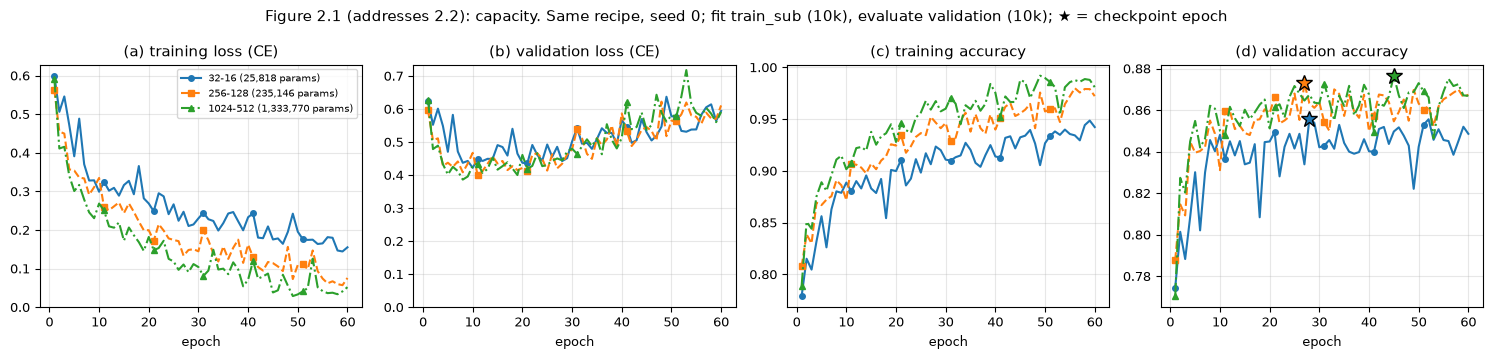

,params,best epoch,val acc (checkpoint),train acc (checkpoint),min train loss,final train acc,final val acc,final val loss,train time (s)
config,,,,,,,,,
"32-16 (25,818 params)",25818,28,0.856,0.923,0.144,0.942,0.849,0.594,2.139
"256-128 (235,146 params)",235146,27,0.873,0.952,0.057,0.972,0.867,0.611,4.911
"1024-512 (1,333,770 params)",1333770,45,0.877,0.988,0.029,0.981,0.867,0.591,18.450


In [16]:
cap_ids = [("E2.2_small", [32, 16]), ("E2.1_baseline", [256, 128]), ("E2.2_large", [1024, 512])]
cap_hists = [mlp_run(i, hidden=h)[1] for i, h in cap_ids]
cap_labels = [f"{'-'.join(map(str, h))} ({hh['n_params']:,} params)" for (_, h), hh in zip(cap_ids, cap_hists)]
plot_curves(cap_hists, cap_labels, "Figure 2.1 (addresses 2.2): capacity. Same recipe, seed 0; "
            "fit train_sub (10k), evaluate validation (10k); ★ = checkpoint epoch", "fig2_1_capacity")
cap_table = summarise(cap_hists, cap_labels); cap_table

In [17]:
for (i, h), hh in zip(cap_ids, cap_hists):
    if i != "E2.1_baseline":
        log_experiment(id=i, task="2.2",
                       question="What does capacity do to training fit and validation performance?",
                       hypothesis="More capacity lowers training loss; validation gains shrink",
                       changed_variable=f"hidden widths {h}", fixed_conditions="baseline recipe, seed 0",
                       split="fit train_sub / eval val", seed=0, configuration=json.dumps(hh["config"]),
                       metric="val accuracy at checkpoint; min train loss",
                       result=f"val {hh['best_val_acc']:.4f}, min train loss {np.nanmin(hh['train_loss']):.3f}",
                       output_path=f"results/runs/{i}.json")

**Table 2.1 (addresses 2.2).** Capacity comparison (validation, seed 0). "Checkpoint" = epoch of best
validation accuracy.

**Analysis 2.2 (capacity).**
* *Observation (training fit).* Training loss is ordered by capacity throughout training (Figure 2.1a):
  minimum training loss 0.144 (small) → 0.057 (baseline) → 0.029 (large); final training accuracy
  0.942 → 0.972 → 0.981.
* *Observation (validation).* Validation accuracy at the checkpoint is 0.856 → 0.873 → 0.877. Going from
  26k to 235k parameters (9×) gained **+1.7 points**; going from 235k to 1.33M (5.7×) gained only
  **+0.4 points** (≈ 40 images out of 10,000). All three MLPs beat logistic regression (0.844) and k-NN (0.822).
* *Observation (overfitting).* For **all three** sizes, validation loss reaches its minimum (~0.40) around
  epochs 10–20 and then rises to ~0.6 by epoch 60, while training loss keeps falling (Figure 2.1a vs b).
  Validation accuracy stays roughly flat. The networks become over-confident on the validation images they
  get wrong, which raises the loss without changing many argmax decisions.
* *Interpretation.* Extra capacity mainly improved **training fit**. It improved validation performance
  only from small to baseline; beyond that, the gain is smaller than the epoch-to-epoch fluctuation of the
  validation curve (±1 point, Figure 2.1d), so it is not convincing from one seed. Part 3 measures the
  seed-to-seed spread for scale.
* *Capacity vs optimisation.* "Capacity" is what a network *could* fit; the training curve shows what the
  optimiser *did* fit within this budget. All three runs trained stably (no divergence), and the larger
  networks reached lower training loss with the *same* number of updates, so the training-fit ordering is
  consistent with capacity. However, the small network's training loss was still falling at epoch 60, so
  part of its gap may be **under-optimisation** rather than a hard capacity limit. Larger networks are
  also often *easier* to optimise. To separate the two, I would train the small model to convergence
  (more epochs or a tuned learning rate) and check whether its training loss plateaus above the others'.
* *Caveat.* Picking the maximum of a noisy validation curve is optimistically biased; noisier runs get
  more "lucky" peaks. Wall-clock cost grows with size: 2.0 s → 4.8 s → 18.6 s.

### 2.3 Experiment B: optimisation — learning rate

**Changed variable:** learning rate η ∈ {0.005, **0.05** (baseline), 0.25}, everything else fixed
(architecture 256-128, momentum 0.9, batch 128, 60 epochs, seed 0).

**Why learning rate:** it is the single setting that most directly controls *how* gradient descent moves
through the loss surface: the step size of every update. A 10× smaller and a 5× larger value show the
two failure modes, too slow and unstable, around the baseline. With momentum 0.9 the effective step is
about η/(1−0.9) = 10η, so η = 0.25 is aggressive.

*Hypothesis:* η = 0.005 learns smoothly but slowly (still improving at epoch 60); η = 0.25 is noisy or
unstable; the baseline sits in between.

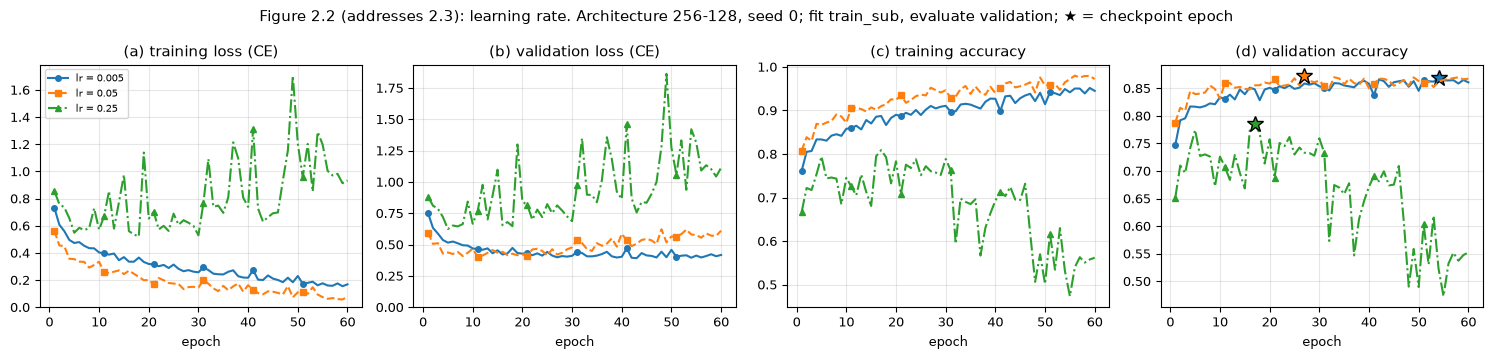

,params,best epoch,val acc (checkpoint),train acc (checkpoint),min train loss,final train acc,final val acc,final val loss,train time (s)
config,,,,,,,,,
lr = 0.005,235146,54,0.869,0.949,0.155,0.945,0.861,0.417,4.931
lr = 0.05,235146,27,0.873,0.952,0.057,0.972,0.867,0.611,4.911
lr = 0.25,235146,17,0.785,0.809,0.520,0.562,0.552,1.113,4.615


In [18]:
lr_ids = [("E2.3_lr0.005", 0.005), ("E2.1_baseline", 0.05), ("E2.3_lr0.25", 0.25)]
lr_hists = [mlp_run(i, lr=v)[1] for i, v in lr_ids]
lr_labels = [f"lr = {v}" for _, v in lr_ids]
plot_curves(lr_hists, lr_labels, "Figure 2.2 (addresses 2.3): learning rate. Architecture 256-128, seed 0; "
            "fit train_sub, evaluate validation; ★ = checkpoint epoch", "fig2_2_learning_rate")
lr_table = summarise(lr_hists, lr_labels); lr_table

In [19]:
for (i, v), hh in zip(lr_ids, lr_hists):
    if i != "E2.1_baseline":
        log_experiment(id=i, task="2.3", question="How does the learning rate change training dynamics?",
                       hypothesis="small lr slow but smooth; large lr unstable",
                       changed_variable=f"lr={v}", fixed_conditions="256-128, momentum 0.9, batch 128, 60 ep, seed 0",
                       split="fit train_sub / eval val", seed=0, configuration=json.dumps(hh["config"]),
                       metric="val accuracy at checkpoint; loss curves",
                       result=f"val {hh['best_val_acc']:.4f} @ ep {hh['best_epoch']}",
                       output_path=f"results/runs/{i}.json")

**Table 2.2 (addresses 2.3).** Learning-rate comparison (validation, seed 0).

**Analysis 2.3 (learning rate).**
* *Observation.* **η = 0.005**: smooth, monotone curves, but slow; the training loss (0.155 at the end) is
  still falling at epoch 60 and the best validation epoch is 54 (0.869). **η = 0.05**: the fastest fit;
  best validation 0.873 already at epoch 27, after which validation loss rises (overfitting).
  **η = 0.25**: unstable; the training loss spikes repeatedly and training accuracy *collapses* from
  ~0.80 to 0.56 by epoch 60. Its best validation accuracy is only 0.785 (epoch 17).
* *Interpretation.* The learning rate scales every update. Too small: each step barely reduces the loss,
  so the model is under-trained within a fixed budget. Too large: with momentum 0.9 the effective step
  (~10η = 2.5) overshoots the minima of the loss surface, so updates bounce out of good regions instead of
  settling. The training loss going *up* is the signature of an optimisation failure, not of capacity or
  overfitting.
* Interestingly, η = 0.005 ends with a much lower validation loss (0.417 vs 0.611) than the baseline. It
  has fitted the training set less tightly, so slow optimisation acts like **implicit early stopping**.
* *Fairness caveats specific to the learning rate.*
  1. The **fixed 60-epoch budget** favours larger rates: η = 0.005 has not converged, and with ~10× more
     epochs it might match or beat the baseline. The comparison is "under this budget", not "in general".
  2. η interacts with **momentum and batch size** (effective step ≈ η/(1−μ), gradient noise ∝ 1/batch),
     so these results apply to μ = 0.9 and batch 128 only.
  3. No learning-rate schedule is used. A decaying schedule could stabilise η = 0.25 late in training.
  4. Single seed; a "max over noisy epochs" checkpoint rewards noisy runs.

---
## Part 3 — Overfitting, regularisation and randomness

**Recognising overfitting.** In Part 2 the unregularised baseline already overfits: after ~epoch 15 the
training loss keeps falling towards 0 while the validation loss *rises* (0.40 → 0.61). The network
memorises the 10k training images and becomes over-confident on validation images.

### 3.1 Regularisation strategies (explored on validation, seed 0)

The architecture (256-128) and the training recipe stay fixed; only the regulariser changes.

| Strategy | Implementation | Settings | How it should help |
|---|---|---|---|
| **None** (baseline) | – | – | reference |
| **L2 weight decay** | adds `weight_decay * w` to each weight gradient in `sgd_momentum_step` (= gradient of $\frac{\lambda}{2}\lVert w\rVert^2$), weights only, not biases | λ ∈ {1e-4, 5e-4, 2e-3} | keeps weights small → smoother function, less extreme logits (less over-confidence) |
| **Dropout** | `nn.Dropout(p)` after each hidden ReLU; active in `model.train()`, off in `model.eval()` | p ∈ {0.2, 0.5} | randomly removes units during training, so the network cannot rely on fragile co-adapted features; like averaging many thinned networks |
| **Early stopping** | the checkpoint rule (best validation epoch) applied to the *unregularised* run | – | stops before memorisation; compare checkpoint vs final epoch |

**Comparable loss definitions.** All plotted losses are the *data* cross-entropy only (the L2 penalty is
not added), measured in `eval` mode (dropout off) on the full training and validation sets after each
epoch, so the regularised and unregularised curves measure the same quantity.

In [20]:
reg_ids = [("E2.1_baseline", {}, "none"),
           ("E3.1_wd1e-4", {"weight_decay": 1e-4}, "L2 λ=1e-4"),
           ("E3.1_wd5e-4", {"weight_decay": 5e-4}, "L2 λ=5e-4"),
           ("E3.1_wd2e-3", {"weight_decay": 2e-3}, "L2 λ=2e-3"),
           ("E3.1_drop0.2", {"dropout": 0.2}, "dropout p=0.2"),
           ("E3.1_drop0.5", {"dropout": 0.5}, "dropout p=0.5")]
reg_hists = [mlp_run(i, **o)[1] for i, o, _ in reg_ids]
reg_labels = [lab for _, _, lab in reg_ids]
reg_table = summarise(reg_hists, reg_labels).drop(columns=["params"])
reg_table["min val loss"] = [np.nanmin(h["val_loss"]) for h in reg_hists]
reg_table["final gap (train−val acc)"] = reg_table["final train acc"] - reg_table["final val acc"]
for (i, o, lab), h in zip(reg_ids[1:], reg_hists[1:]):
    log_experiment(id=i, task="3.1", question="Which regulariser best reduces overfitting of the 256-128 MLP?",
                   hypothesis="Regularisation lowers final val loss and the train-val gap",
                   changed_variable=lab, fixed_conditions="256-128, lr 0.05, mom 0.9, batch 128, 60 ep",
                   split="fit train_sub / eval val", seed=0, configuration=json.dumps(h["config"]),
                   metric="val acc (checkpoint & final), final val loss",
                   result=f"ckpt {h['best_val_acc']:.4f}; final {h['val_acc'][-1]:.4f}; final val loss {h['val_loss'][-1]:.3f}",
                   output_path=f"results/runs/{i}.json")
reg_table

,best epoch,val acc (checkpoint),train acc (checkpoint),min train loss,final train acc,final val acc,final val loss,train time (s),min val loss,final gap (train−val acc)
config,,,,,,,,,,
none,27,0.873,0.952,0.057,0.972,0.867,0.611,4.911,0.400,0.105
L2 λ=1e-4,54,0.870,0.970,0.082,0.964,0.865,0.564,5.289,0.399,0.099
L2 λ=5e-4,39,0.872,0.951,0.116,0.958,0.869,0.416,5.152,0.387,0.090
L2 λ=2e-3,31,0.862,0.913,0.241,0.907,0.856,0.403,5.178,0.385,0.051
dropout p=0.2,42,0.872,0.934,0.154,0.936,0.865,0.440,4.544,0.381,0.071
dropout p=0.5,52,0.854,0.895,0.273,0.888,0.850,0.438,4.587,0.414,0.038


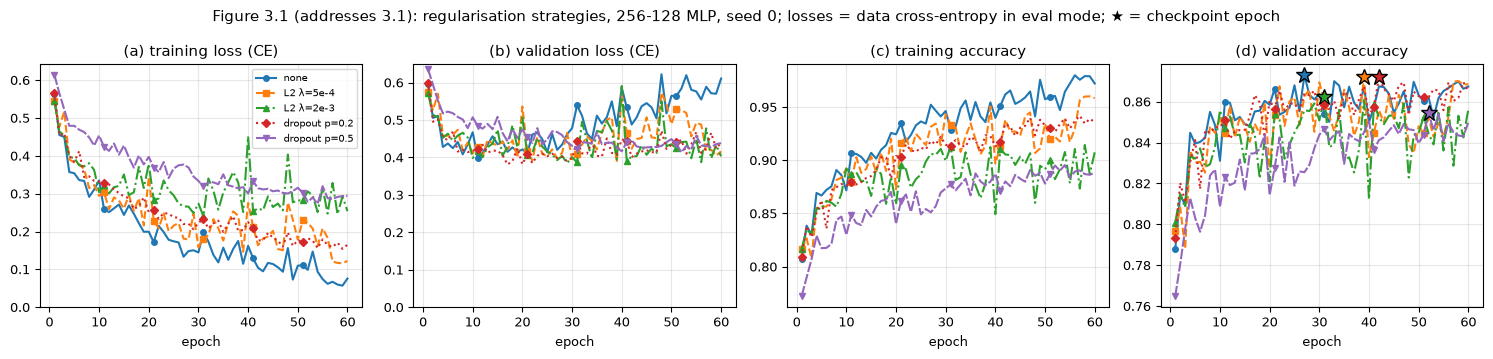

In [21]:
plot_curves([reg_hists[0], reg_hists[2], reg_hists[3], reg_hists[4], reg_hists[5]],
            [reg_labels[0], reg_labels[2], reg_labels[3], reg_labels[4], reg_labels[5]],
            "Figure 3.1 (addresses 3.1): regularisation strategies, 256-128 MLP, seed 0; "
            "losses = data cross-entropy in eval mode; ★ = checkpoint epoch", "fig3_1_regularisers")

**Table 3.1 (addresses 3.1).** Regularisation strategies (validation, seed 0). The λ = 1e-4 run is in the
table but omitted from Figure 3.1 for readability.

**Analysis 3.1 (what regularisation changed).**
* *Observation: overfitting is reduced.* Every regulariser lowers the final validation loss (0.611 with
  none → 0.40–0.56) and narrows the final train–validation accuracy gap (0.105 → 0.04–0.10). In Figure 3.1b
  the unregularised validation loss climbs after epoch ~20, while the L2 λ ≥ 5e-4 and dropout curves
  stay flat around 0.40–0.45. Training loss is correspondingly higher (Figure 3.1a): the regulariser stops
  the network from driving training loss to zero.
* *Observation: accuracy is not improved.* Checkpoint validation accuracy for none / L2 5e-4 / dropout 0.2
  is 0.873 / 0.872 / 0.872, which are indistinguishable. Too much regularisation **hurts** (L2 2e-3: 0.862;
  dropout 0.5: 0.854): training accuracy falls to ~0.90, i.e. the model starts to *underfit*. λ = 1e-4 is
  too weak to change much.
* *Interpretation.* Overfitting in this model shows up mainly as **over-confidence** (huge logits on
  training images, confident mistakes on validation images), which cross-entropy punishes heavily, rather
  than as many more wrong argmax decisions. L2 shrinks weights, so logits stay moderate; dropout forces
  redundant features, so no single unit dominates. Both make the network's probabilities better
  calibrated, which is what the validation loss measures.
* *Early stopping* is also a regulariser here: the unregularised checkpoint (epoch 27, 0.873) already
  captures the best accuracy, and its validation loss near that point (~0.42) is far below its final 0.611.
  For accuracy alone, early stopping is as good as L2 or dropout; the explicit regularisers matter if we
  need reliable probabilities (e.g. the threshold decisions of Part 1.5) or cannot afford a validation-based stop.
* *Selection.* Following the rule written in the next cell (highest checkpoint validation accuracy,
  excluding the baseline), **dropout p = 0.2** is carried into 3.2; L2 λ = 5e-4 was a near-tie.

### 3.2 Randomness: three seeds for the two main configurations

The two configurations behind the main conclusion, **unregularised** vs **the regulariser selected on
validation in 3.1**, are trained with seeds 0, 1, 2 (seed 0 runs are reused). The data split
(seed 708) and the 10k fitting subset are fixed.

**Sources of randomness controlled by the seed:** (1) weight initialisation, (2) minibatch order,
(3) dropout masks. **Fixed:** data split and subsets, the order of validation images, all hyperparameters.
**Not controlled:** floating-point non-associativity in multi-threaded CPU kernels (tiny differences
between machines are possible).

In [22]:
# Selection rule (fixed before running seeds 1 and 2): the regulariser with the highest checkpoint
# validation accuracy in Table 3.1, excluding the baseline.
sel_label = reg_table.drop(index="none")["val acc (checkpoint)"].idxmax()
sel_id, sel_over, _ = next(r for r in reg_ids if r[2] == sel_label)
print("Selected regulariser on validation:", sel_label, sel_over)

SEEDS = [0, 1, 2]
seed_runs = {"none": [], sel_label: []}
for sd in SEEDS:
    seed_runs["none"].append(mlp_run("E2.1_baseline" if sd == 0 else f"E3.2_none_s{sd}", seed=sd)[1])
    seed_runs[sel_label].append(mlp_run(sel_id if sd == 0 else f"E3.2_{sel_id.split('_')[1]}_s{sd}",
                                        seed=sd, **sel_over)[1])

rows = []
for name, hs in seed_runs.items():
    for sd, h in zip(SEEDS, hs):
        rows.append({"config": name, "seed": sd, "val acc (checkpoint)": h["best_val_acc"],
                     "best epoch": h["best_epoch"], "final val acc": h["val_acc"][-1],
                     "final val loss": h["val_loss"][-1], "min val loss": np.nanmin(h["val_loss"]),
                     "final train acc": h["train_acc"][-1],
                     "final gap": h["train_acc"][-1] - h["val_acc"][-1]})
seed_df = pd.DataFrame(rows)
metrics = ["val acc (checkpoint)", "final val acc", "final val loss", "min val loss", "final gap"]
agg = seed_df.groupby("config", sort=False)[metrics].agg(["mean", lambda x: x.std(ddof=1)])
agg.columns = [f"{m} {'mean' if s == 'mean' else 'std'}" for m, s in agg.columns]
display(seed_df.set_index(["config", "seed"]).round(4))
agg.T.round(4)

Selected regulariser on validation: dropout p=0.2 {'dropout': 0.2}


val acc (checkpoint)  best epoch  final val acc  \
config        seed                                                    
none          0                    0.873          27          0.867   
              1                    0.870          19          0.864   
              2                    0.873          46          0.869   
dropout p=0.2 0                    0.872          42          0.865   
              1                    0.870          35          0.870   
              2                    0.869          41          0.865   

                    final val loss  min val loss  final train acc  final gap  
config        seed                                                            
none          0              0.611         0.400            0.972      0.105  
              1              0.646         0.381            0.963      0.099  
              2              0.595         0.400            0.972      0.103  
dropout p=0.2 0              0.440         0.381            0.936      0.071  
              1              0.428         0.391            0.941      0.071  
              2              0.427         0.384            0.935      0.070

config,none,dropout p=0.2
val acc (checkpoint) mean,0.872,8.705e-01
val acc (checkpoint) std,0.001,1.400e-03
final val acc mean,0.867,8.667e-01
final val acc std,0.002,2.800e-03
final val loss mean,0.617,4.317e-01
final val loss std,0.026,6.800e-03
min val loss mean,0.393,3.855e-01
min val loss std,0.011,5.200e-03
final gap mean,0.103,7.080e-02
final gap std,0.003,5.000e-04


**Table 3.2 (addresses 3.2).** Top: every seed. Bottom: mean and **sample** standard deviation (ddof = 1)
over the 3 seeds. Validation set, 10,000 images.

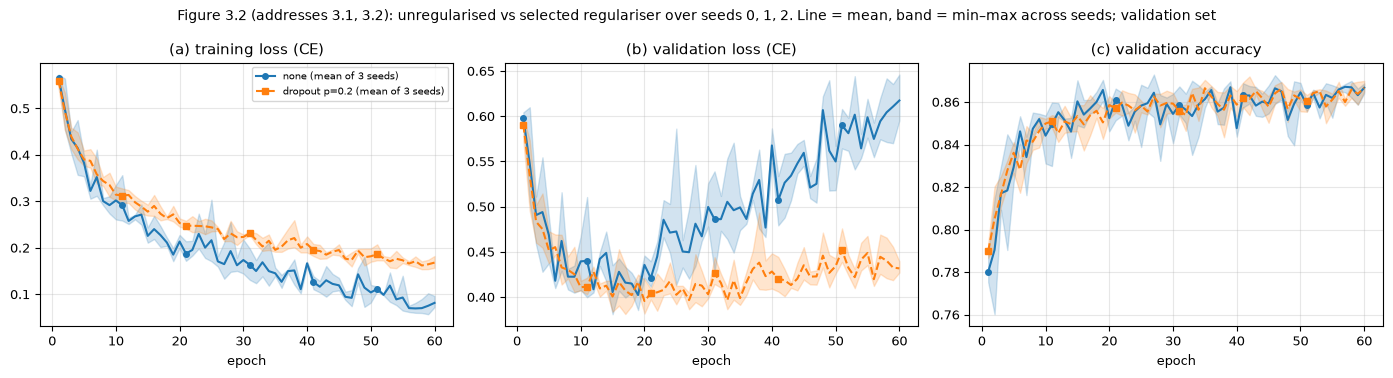

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for (name, hs), st in zip(seed_runs.items(), STYLES):
    for key, ax in zip(["train_loss", "val_loss", "val_acc"], axes):
        arr = np.array([h[key] for h in hs]); ep = np.arange(1, arr.shape[1] + 1)
        line, = ax.plot(ep, arr.mean(0), label=f"{name} (mean of 3 seeds)", markevery=10, ms=4, **st)
        ax.fill_between(ep, arr.min(0), arr.max(0), alpha=0.2, color=line.get_color())
for ax, t in zip(axes, ["(a) training loss (CE)", "(b) validation loss (CE)", "(c) validation accuracy"]):
    ax.set_title(t); ax.set_xlabel("epoch")
axes[0].legend(fontsize=7)
fig.suptitle("Figure 3.2 (addresses 3.1, 3.2): unregularised vs selected regulariser over seeds 0, 1, 2. "
             "Line = mean, band = min–max across seeds; validation set", fontsize=10)
fig.tight_layout(); savefig(fig, "fig3_2_seeds"); plt.show()

In [24]:
diff = (seed_df[seed_df.config == sel_label]["val acc (checkpoint)"].values
        - seed_df[seed_df.config == "none"]["val acc (checkpoint)"].values)
print("Paired difference in checkpoint val acc (regularised − none) per seed:", np.round(diff, 4),
      f"| mean {diff.mean():+.4f}, sample std {diff.std(ddof=1):.4f}")
diff_f = (seed_df[seed_df.config == sel_label]["final val loss"].values
          - seed_df[seed_df.config == "none"]["final val loss"].values)
print("Paired difference in final val loss (regularised − none) per seed:", np.round(diff_f, 3))
log_experiment(id="E3.2", task="3.2", question="Is the regularisation effect larger than seed variability?",
               hypothesis="Final val loss improvement is consistent across seeds; accuracy gain is small",
               changed_variable=f"none vs {sel_label}, seeds {SEEDS}",
               fixed_conditions="split seed 708, train_sub, 256-128, lr 0.05, 60 ep",
               split="fit train_sub / eval val", seed=str(SEEDS),
               configuration=f"selected: {sel_over}", metric="val acc (checkpoint), final val loss; mean ± sample std",
               result="; ".join(f"{c}: {agg.loc[c, 'val acc (checkpoint) mean']:.4f} ± {agg.loc[c, 'val acc (checkpoint) std']:.4f}"
                                for c in agg.index),
               output_path="figures/fig3_2_seeds.png");

Paired difference in checkpoint val acc (regularised − none) per seed: [-0.0009  0.     -0.0034] | mean -0.0014, sample std 0.0018
Paired difference in final val loss (regularised − none) per seed: [-0.171 -0.218 -0.168]


**Analysis 3.2 (randomness).**
* *Observation.* Across seeds 0–2, checkpoint validation accuracy is **0.872 ± 0.001** (none) vs
  **0.871 ± 0.001** (dropout 0.2) (mean ± sample std). The paired difference per seed is −0.0009, 0.0000,
  −0.0034, so no difference can be claimed. Final validation loss is **0.617 ± 0.026** (none) vs
  **0.432 ± 0.007** (dropout): the reduction (0.17–0.22) is about **7× the seed standard deviation** and
  has the same sign for all three seeds. The final train–val gap is 0.103 ± 0.003 vs 0.071 ± 0.0005.
* *Interpretation.* Seed randomness (initialisation, minibatch order, dropout masks) moves validation
  accuracy by about ±0.1–0.3 points: about 10–30 images. Any accuracy difference of that size between two
  configurations in Parts 2–3 (e.g. baseline vs large network, +0.4 points from one seed) should be treated
  as **not established**. Randomness affects the unregularised model more in the *late* epochs: its
  validation-loss band widens after epoch 30 (Figure 3.2b), because which training images get memorised
  depends on the random path taken. Dropout's band stays narrow.
  Randomness also changes **which epoch** is selected (none: epochs 19, 27, 46), so the checkpoint epoch
  itself is a noisy quantity.
* *Conclusion (bounded).* On this data (10k training images, 256-128 MLP, 60 epochs, momentum SGD),
  dropout 0.2 reliably reduces over-confidence and the generalisation gap, but does not improve validation
  accuracy relative to early stopping. Three seeds give a rough estimate of the spread, not statistical
  proof; a confidence interval would need more seeds.